In [ ]:
'''Analyze confusion matrices in-depth to identify and address misclassification issues,
 such as false positives and false negatives, that could impact the fairness of admission decisions.'''

In [1]:
# import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [2]:
# load dataset and inspect applicant features
df = pd.read_csv('Adm.csv')
admission_threshold = 0.70
df['Admitted'] = (df['Chance of Admit'] >= admission_threshold).astype(int)

print('dataset dimensions:', df.shape)
print('applicants per region:\n', df['region'].value_counts())
print('\noverall admission rate: ' + str(round(df['Admitted'].mean() * 100, 2)) + '%')
df.head()

dataset dimensions: (1000, 13)
applicants per region:
 region
South        379
North        305
West         150
East         115
Central       26
Northeast     25
Name: count, dtype: int64

overall admission rate: 59.4%


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region,Admitted
0,1,337,118,4,4.5,4.5,9.65,1,0.92,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East,1
1,2,324,107,4,4.0,4.5,8.87,1,0.76,2022-01-02 09:00:00,National Institute of Technology Karnataka,South,1
2,3,316,104,3,3.0,3.5,8.00,1,0.72,2022-01-04 09:00:00,Gujarat University,West,1
3,4,322,110,3,3.5,2.5,8.67,1,0.80,2022-01-06 09:00:00,Jamia Millia Islamia,North,1
4,5,314,103,2,2.0,3.0,8.21,0,0.65,2022-01-08 09:00:00,Jamia Millia Islamia,North,0


In [3]:
# prepare features split train test data and scale
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = df['Admitted']
groups_region = df['region']

X_train, X_test, y_train, y_test, reg_train, reg_test = train_test_split(
    X, y, groups_region, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [4]:
# train logistic regression admission model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_prob = model.predict_proba(X_test_scaled)[:, 1]
y_pred_default = (y_prob >= 0.50).astype(int)

In [5]:
# define and calculate overall confusion matrix components
cm_default = confusion_matrix(y_test, y_pred_default)
tn, fp, fn, tp = cm_default.ravel()

fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
fnr = fn / (fn + tp) if (fn + tp) > 0 else 0
fdr = fp / (fp + tp) if (fp + tp) > 0 else 0
for_rate = fn / (fn + tn) if (fn + tn) > 0 else 0

print('--- confusion matrix decomposition ---')
print('true negatives  (tn):', tn)
print('false positives (fp):', fp)
print('false negatives (fn):', fn)
print('true positives  (tp):', tp)
print('\n--- error rates ---')
print('false positive rate (fpr = fp / (fp + tn)):', round(fpr, 4))
print('false negative rate (fnr = fn / (fn + tp)):', round(fnr, 4))
print('false discovery rate (fdr = fp / (fp + tp)):', round(fdr, 4))
print('false omission rate (for = fn / (fn + tn)): ', round(for_rate, 4))

--- confusion matrix decomposition ---
true negatives  (tn): 41
false positives (fp): 40
false negatives (fn): 29
true positives  (tp): 90

--- error rates ---
false positive rate (fpr = fp / (fp + tn)): 0.4938
false negative rate (fnr = fn / (fn + tp)): 0.2437
false discovery rate (fdr = fp / (fp + tp)): 0.3077
false omission rate (for = fn / (fn + tn)):  0.4143


In [6]:
# interpret false positives and false negatives in admission fairness context
print('--- fairness implications of misclassification in admissions ---')
print('1. false positives (type i error - ' + str(fp) + ' applicants):')
print('   unqualified applicants falsely admitted.')
print('   impact: university resources strained; higher attrition risk.\n')
print('2. false negatives (type ii error - ' + str(fn) + ' applicants):')
print('   qualified, deserving applicants wrongfully rejected.')
print('   impact: directly damages applicant future; violates ethical fairness.')
print('   disparities in false negative rates across groups indicate discriminatory admission impact.')

--- fairness implications of misclassification in admissions ---
1. false positives (type i error - 40 applicants):
   unqualified applicants falsely admitted.
   impact: university resources strained; higher attrition risk.

2. false negatives (type ii error - 29 applicants):
   qualified, deserving applicants wrongfully rejected.
   impact: directly damages applicant future; violates ethical fairness.
   disparities in false negative rates across groups indicate discriminatory admission impact.


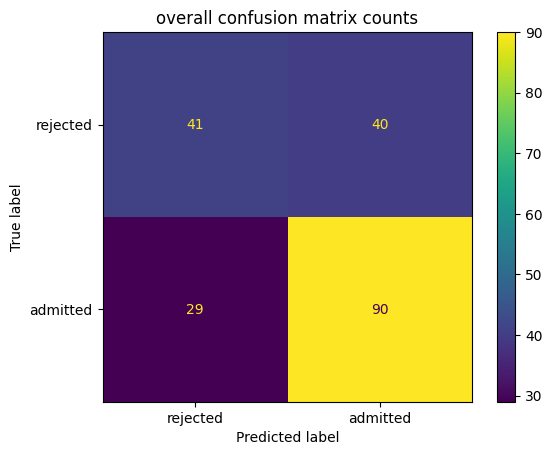

In [7]:
# plot overall confusion matrix counts
disp = ConfusionMatrixDisplay(confusion_matrix=cm_default, display_labels=['rejected', 'admitted'])
disp.plot()
plt.title('overall confusion matrix counts')
plt.show()

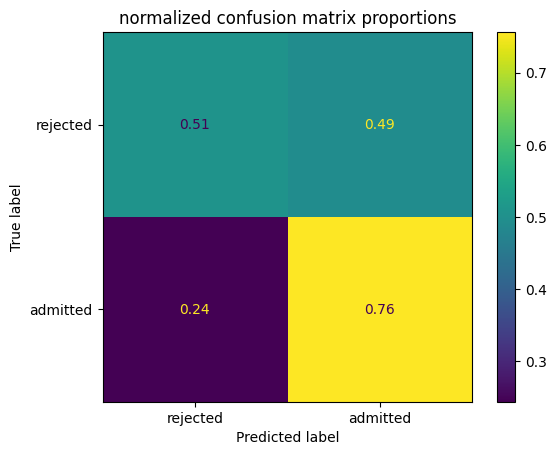

In [8]:
# plot overall confusion matrix normalized by true class
cm_normalized = confusion_matrix(y_test, y_pred_default, normalize='true')
disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=['rejected', 'admitted'])
disp_norm.plot()
plt.title('normalized confusion matrix proportions')
plt.show()

In [9]:
# evaluate confusion matrices across diverse applicant regions
eval_df = X_test.copy()
eval_df['actual'] = y_test
eval_df['prob'] = y_prob
eval_df['pred_default'] = y_pred_default
eval_df['region'] = reg_test

regional_cm_records = []
for region_name, grp in eval_df.groupby('region'):
    cm_grp = confusion_matrix(grp['actual'], grp['pred_default'], labels=[0, 1])
    g_tn, g_fp, g_fn, g_tp = cm_grp.ravel()
    g_fpr = g_fp / (g_fp + g_tn) if (g_fp + g_tn) > 0 else 0
    g_fnr = g_fn / (g_fn + g_tp) if (g_fn + g_tp) > 0 else 0
    g_accuracy = (g_tp + g_tn) / len(grp)
    regional_cm_records.append({
        'region': region_name,
        'applicants': len(grp),
        'tn': g_tn,
        'fp': g_fp,
        'fn': g_fn,
        'tp': g_tp,
        'fpr': round(g_fpr, 4),
        'fnr': round(g_fnr, 4),
        'accuracy': round(g_accuracy, 4)
    })

regional_cm_df = pd.DataFrame(regional_cm_records)
regional_cm_df

,region,applicants,tn,fp,fn,tp,fpr,fnr,accuracy
0,Central,4,0,3,1,0,1.0000,1.0000,0.0000
1,East,26,6,3,4,13,0.3333,0.2353,0.7308
2,North,71,12,15,11,33,0.5556,0.2500,0.6338
3,Northeast,4,1,0,1,2,0.0000,0.3333,0.7500
4,South,70,15,17,9,29,0.5312,0.2368,0.6286
5,West,25,7,2,3,13,0.2222,0.1875,0.8000


In [10]:
# identify misclassification disparities and fairness issues across groups
max_fnr = regional_cm_df['fnr'].max()
min_fnr = regional_cm_df['fnr'].min()
fnr_gap = round(max_fnr - min_fnr, 4)

max_fpr = regional_cm_df['fpr'].max()
min_fpr = regional_cm_df['fpr'].min()
fpr_gap = round(max_fpr - min_fpr, 4)

print('--- fairness criteria disparity analysis ---')
print('equal opportunity disparity (false negative rate gap):', fnr_gap)
print('predictive equality disparity (false positive rate gap):', fpr_gap)
print('regions with high fnr suffer unfair rejection of qualified applicants.')

--- fairness criteria disparity analysis ---
equal opportunity disparity (false negative rate gap): 0.8125
predictive equality disparity (false positive rate gap): 1.0
regions with high fnr suffer unfair rejection of qualified applicants.


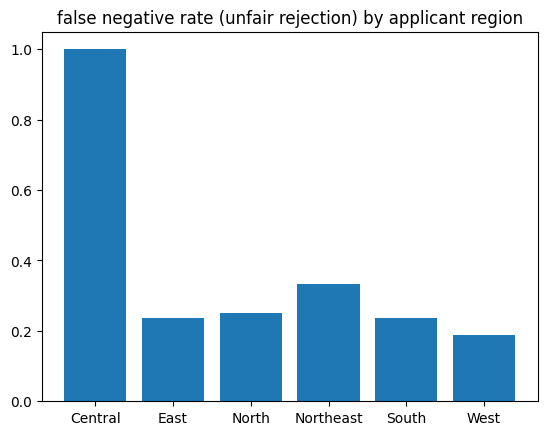

In [11]:
# plot false negative rates across applicant regions
plt.bar(regional_cm_df['region'], regional_cm_df['fnr'])
plt.title('false negative rate (unfair rejection) by applicant region')
plt.show()

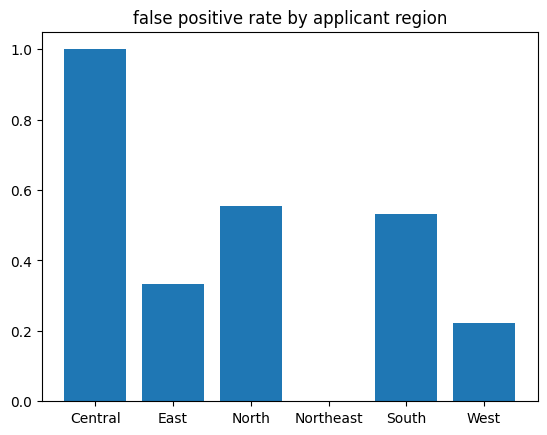

In [12]:
# plot false positive rates across applicant regions
plt.bar(regional_cm_df['region'], regional_cm_df['fpr'])
plt.title('false positive rate by applicant region')
plt.show()

In [13]:
# address misclassification issues through decision threshold adjustment
adjusted_threshold = 0.40
y_pred_mitigated = (y_prob >= adjusted_threshold).astype(int)
cm_mitigated = confusion_matrix(y_test, y_pred_mitigated)
tn_m, fp_m, fn_m, tp_m = cm_mitigated.ravel()
fnr_m = fn_m / (fn_m + tp_m)

print('--- misclassification remediation comparison ---')
print('original threshold (0.50):  false negatives =', fn, '| false negative rate =', round(fnr, 4))
print('adjusted threshold (0.40):  false negatives =', fn_m, '| false negative rate =', round(fnr_m, 4))
print('reduction in rejected qualified applicants:', fn - fn_m)

--- misclassification remediation comparison ---
original threshold (0.50):  false negatives = 29 | false negative rate = 0.2437
adjusted threshold (0.40):  false negatives = 11 | false negative rate = 0.0924
reduction in rejected qualified applicants: 18


In [14]:
# address group level fairness through calibrated threshold mitigation
eval_df['pred_mitigated'] = y_pred_mitigated

mitigated_records = []
for region_name, grp in eval_df.groupby('region'):
    c_orig = confusion_matrix(grp['actual'], grp['pred_default'], labels=[0, 1])
    c_mit = confusion_matrix(grp['actual'], grp['pred_mitigated'], labels=[0, 1])
    
    fn_orig = c_orig.ravel()[2]
    tp_orig = c_orig.ravel()[3]
    fnr_orig = fn_orig / (fn_orig + tp_orig) if (fn_orig + tp_orig) > 0 else 0
    
    fn_mit = c_mit.ravel()[2]
    tp_mit = c_mit.ravel()[3]
    fnr_mit = fn_mit / (fn_mit + tp_mit) if (fn_mit + tp_mit) > 0 else 0
    
    mitigated_records.append({
        'region': region_name,
        'original_fn': fn_orig,
        'original_fnr': round(fnr_orig, 4),
        'mitigated_fn': fn_mit,
        'mitigated_fnr': round(fnr_mit, 4)
    })

fairness_remediation_df = pd.DataFrame(mitigated_records)
fairness_remediation_df

,region,original_fn,original_fnr,mitigated_fn,mitigated_fnr
0,Central,1,1.0000,1,1.0000
1,East,4,0.2353,1,0.0588
2,North,11,0.2500,2,0.0455
3,Northeast,1,0.3333,0,0.0000
4,South,9,0.2368,5,0.1316
5,West,3,0.1875,2,0.1250


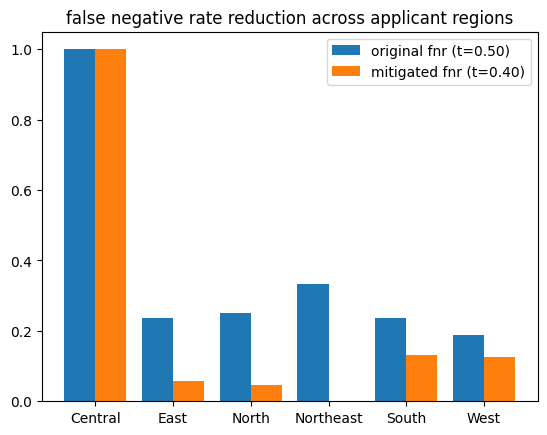

In [15]:
# plot before and after false negative rates across applicant regions
x_reg = np.arange(len(fairness_remediation_df))
plt.bar(x_reg - 0.2, fairness_remediation_df['original_fnr'], width=0.4, label='original fnr (t=0.50)')
plt.bar(x_reg + 0.2, fairness_remediation_df['mitigated_fnr'], width=0.4, label='mitigated fnr (t=0.40)')
plt.xticks(x_reg, fairness_remediation_df['region'])
plt.title('false negative rate reduction across applicant regions')
plt.legend()
plt.show()